In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [4]:
df = pd.read_csv("C:/Users/LENOVO/Downloads/datasets/Telco-Customer-Churn.csv")

In [5]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
print("Dataset Shape:", df.shape)

df.info()

df.describe()

Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
# Check missing values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
# Count duplicate rows
df.duplicated().sum()

0

In [9]:
# Display column data types
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [11]:
# Convert TotalCharges into numeri
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df["TotalCharges"].dtype

dtype('float64')

In [12]:
# Check missing values again reason we changed the total charges into numeric and errors is coerce
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [13]:
df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df.isnull().sum().sum()

0

In [ ]:
#CustomerID is only an identifier. It doesn't provide useful customer behavior information for our model.
df = df.drop("customerID", axis=1)

In [18]:
df.columns


Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [19]:
print("Rows and Columns:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
df.describe()

Rows and Columns: (7043, 20)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   obje

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


# Exploratory Data Analysis (EDA)

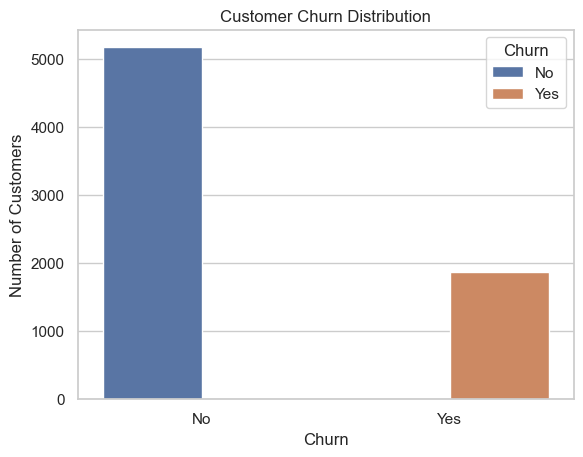

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn", hue="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

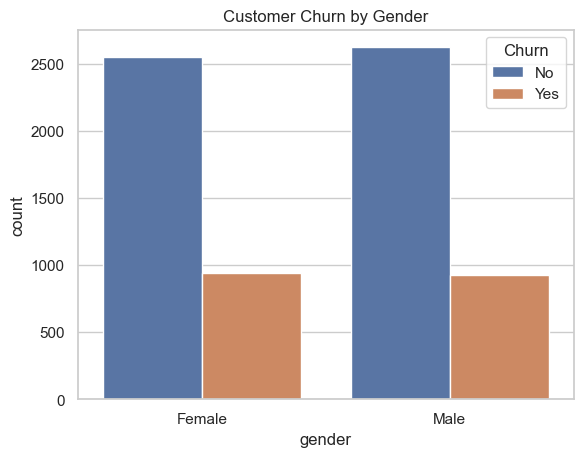

In [27]:
sns.countplot(data=df, x="gender", hue="Churn")

plt.title("Customer Churn by Gender")

plt.show()

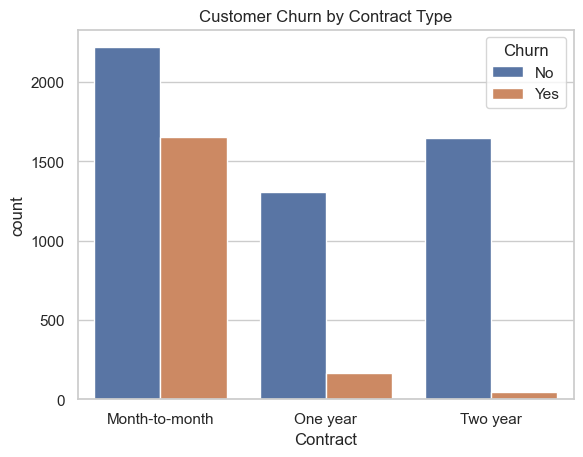

In [31]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")

plt.show()

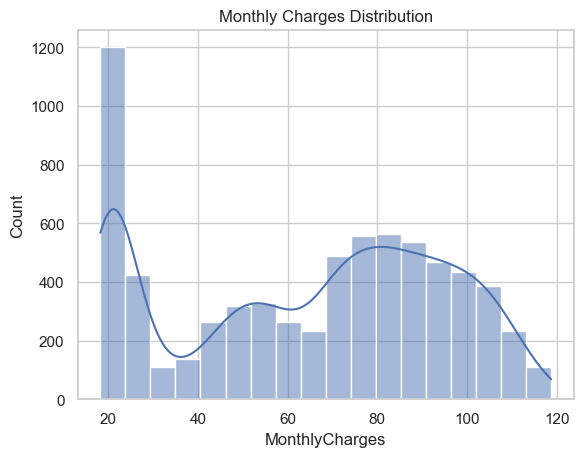

In [32]:
sns.histplot(data=df, x="MonthlyCharges", kde=True)

plt.title("Monthly Charges Distribution")

plt.show()

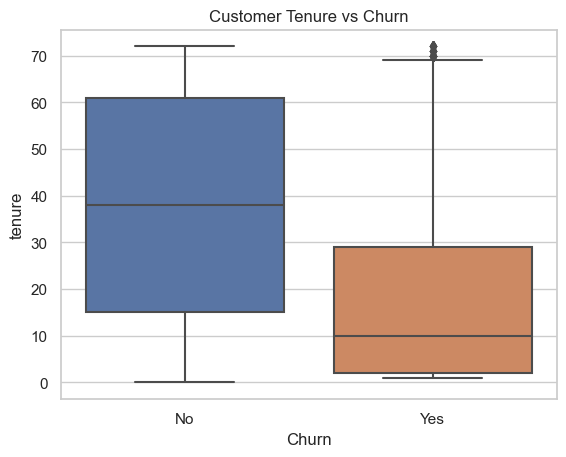

In [33]:
sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure vs Churn")

plt.show()

In [34]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


<AxesSubplot:>

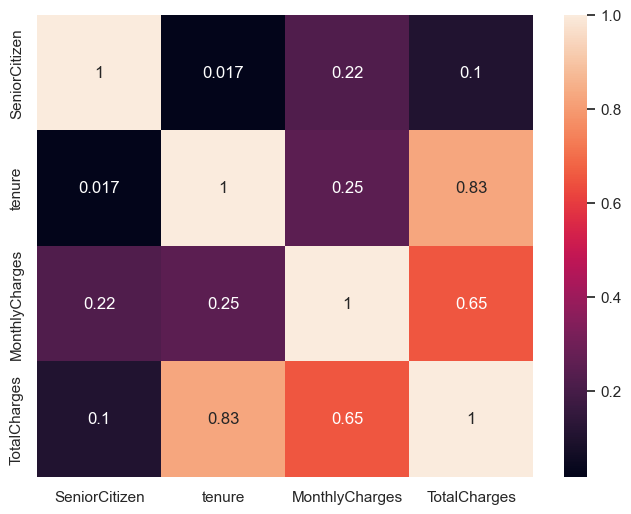

In [35]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(),annot=True)

# Feature Engineering

In [36]:
# Create a new column called TenureGroup

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months",
            "25-48 Months", "49-72 Months"]
)


df[["tenure", "TenureGroup"]].head()

,tenure,TenureGroup
0,1,0-12 Months
1,34,25-48 Months
2,2,0-12 Months
3,45,25-48 Months
4,2,0-12 Months


In [38]:
# Select the six additional service columns
services = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Check which services have the value Yes
df[services] == "Yes"

,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,False,True,False,False,False,False
1,True,False,True,False,False,False
2,True,True,False,False,False,False
3,True,False,True,True,False,False
4,False,False,False,False,False,False
...,...,...,...,...,...,...
7038,True,False,True,True,True,True
7039,False,True,True,False,True,True
7040,True,False,False,False,False,False
7041,False,False,False,False,False,False


In [39]:
# Count the Yes values in each customer row
df["TotalServices"] = (df[services] == "Yes").sum(axis=1)

In [41]:
# Display the result
df[["TotalServices"]].head()

,TotalServices
0,1
1,2
2,2
3,3
4,0


In [42]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,TotalServices
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 Months,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 Months,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 Months,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 Months,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 Months,0


# MACHINE LEARNING MODEL IMPLEMENTATION

In [43]:
# X contains all input features
X = df.drop("Churn", axis=1)

# y contains the target we want to predict
y = df["Churn"]

In [44]:
#THERE ARE SOME CATEGORICAL COLUMNS IN  THE DATASET AND MACHINE LEARNING MODEL WIORKS BEST ON NUMERICAL VALUES SO WE WILL CONVERT IT
#ONE HOT ENCODING
# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Display the converted dataset
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,TotalServices,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,TenureGroup_13-24 Months,TenureGroup_25-48 Months,TenureGroup_49-72 Months
0,0,1,29.85,29.85,1,0,1,0,0,1,...,0,0,0,1,0,1,0,0,0,0
1,0,34,56.95,1889.50,2,1,0,0,1,0,...,0,1,0,0,0,0,1,0,1,0
2,0,2,53.85,108.15,2,1,0,0,1,0,...,0,0,0,1,0,0,1,0,0,0
3,0,45,42.30,1840.75,3,1,0,0,0,1,...,0,1,0,0,0,0,0,0,1,0
4,0,2,70.70,151.65,0,0,0,0,1,0,...,0,0,0,1,0,1,0,0,0,0


In [45]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 34)
Testing data: (1409, 34)


In [47]:
# Import Logistic Regression model
from sklearn.linear_model import LogisticRegression

#MODEL
model = LogisticRegression(max_iter=1000)

# Train the model using training data
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [48]:
# Predict churn for customers in the testing dataset
y_pred = model.predict(X_test)



In [49]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.7970191625266146


In [50]:
# Show precision, recall and F1-score
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [51]:
# Import Random Forest


# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [53]:
# Predict churn for testing customers
rf_predictions = rf_model.predict(X_test)



In [56]:
# Compare actual results with predicted results
rf_accuracy = accuracy_score(y_test, rf_predictions)

# Display accuracy
print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.7885024840312278


In [57]:
# Import classification_report
from sklearn.metrics import classification_report

# Display model performance
print(classification_report(y_test, rf_predictions))

              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.63      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.78      0.79      0.78      1409



In [58]:
# Compare actual results with predicted results
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
print(cm)

[[928 107]
 [179 195]]


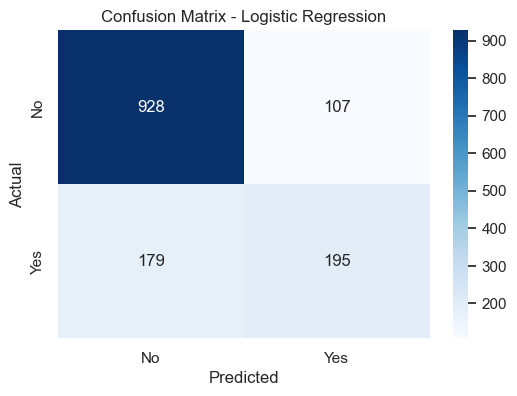

In [59]:
# Set the size of the chart
plt.figure(figsize=(6, 4))

# Create the heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

# Add chart title
plt.title("Confusion Matrix - Logistic Regression")

# Label the axes
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Display the chart
plt.show()

In [60]:
# Compare actual results with Random Forest predictions
rf_cm = confusion_matrix(y_test, rf_predictions)

# Display the confusion matrix
print(rf_cm)

[[931 104]
 [194 180]]


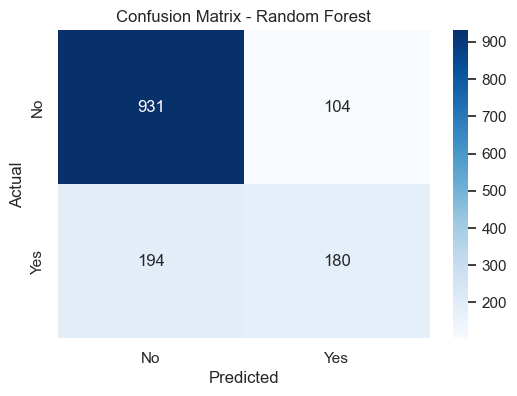

In [61]:
# Set the size of the chart
plt.figure(figsize=(6, 4))

# Create the heatmap
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

# Add chart title
plt.title("Confusion Matrix - Random Forest")

# Label the axes
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Display the chart
plt.show()

### the preprocessing workflow to avoid data leakage.

In [88]:
# Make a copy of our cleaned dataset
data = df.copy()

# Separate customer information from churn status
X = data.drop("Churn", axis=1)

# Churn is the column we want to predict
y = data["Churn"]

# Remove customer ID if it still exists
X = X.drop(columns=["customerID"], errors="ignore")

In [89]:
# Divide data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 21)
Testing data: (1409, 21)


In [90]:
# Create preprocessing steps for numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [91]:
# Create preprocessing steps for categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [92]:
from sklearn.compose import make_column_selector
preprocessor = ColumnTransformer([
    ("numbers", numeric_pipeline,
     make_column_selector(dtype_include="number")),

    ("categories", categorical_pipeline,
     make_column_selector(dtype_include=["object", "category"]))
])


# IMPROVED MODEL TESTING

# LOGISTIC REGRESSION

In [93]:
# Create the model

# Combine preprocessing with the model
from sklearn.pipeline import make_pipeline

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model = make_pipeline(preprocessor, logistic_model)

In [94]:
# Train the model
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numbers',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000024B8AC095B0>),
                                                 ('categories',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle

In [95]:
# Predict customer churn
logistic_predictions = logistic_model.predict(X_test)



In [96]:
print("Accuracy:", accuracy_score(y_test, logistic_predictions))

print(classification_report(y_test, logistic_predictions))

Accuracy: 0.7331440738112136
              precision    recall  f1-score   support

          No       0.90      0.71      0.80      1035
         Yes       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



In [75]:
# Create Logistic Regression without class balancing
logistic_model_2 = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000)
)

# Train the model
logistic_model_2.fit(X_train, y_train)

# Make predictions
predictions_2 = logistic_model_2.predict(X_test)

# Check performance
print("Accuracy:", accuracy_score(y_test, predictions_2))

print(classification_report(y_test, predictions_2))


Accuracy: 0.7991483321504613
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [99]:
# Get the probability of customers leaving
churn_probability = logistic_model_2.predict_proba(X_test)[:, 1]

# Set threshold
threshold = 0.4

# Convert probabilities into Yes (1) and No (0)
threshold_predictions = (churn_probability >= threshold).astype(int)


In [98]:
y_test = y_test.map({"No": 0, "Yes": 1})

In [100]:
# Calculate accuracy
print("Accuracy:", accuracy_score(y_test, threshold_predictions))

# Display classification report
print(classification_report(y_test, threshold_predictions))

Accuracy: 0.7835344215755855
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      1035
           1       0.58      0.66      0.62       374

    accuracy                           0.78      1409
   macro avg       0.73      0.74      0.73      1409
weighted avg       0.79      0.78      0.79      1409



In [101]:
# Set threshold to 0.3
threshold = 0.3

# Generate predictions
predictions_03 = (churn_probability >= threshold).astype(int)

# Evaluate the model
print("Threshold 0.3 Results:")
print(classification_report(y_test, predictions_03))

Threshold 0.3 Results:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409



# RANDOM FOREST

In [102]:
# Create the Random Forest model
rf_model = make_pipeline(
    preprocessor,
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

In [104]:
print("Actual values:", y_test.unique())
print("Predicted values:", np.unique(rf_predictions))

Actual values: [0 1]
Predicted values: ['No' 'Yes']


In [105]:
rf_predictions = pd.Series(rf_predictions).map({
    "No": 0,
    "Yes": 1
}).values

In [106]:
# Check model accuracy
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

# Check precision, recall and F1-score
print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.7799858055358411
              precision    recall  f1-score   support

           0       0.82      0.89      0.86      1035
           1       0.61      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409



In [108]:
print("Actual:", y_test.unique())
print("Predictions:", np.unique(predictions_2))

Actual: [0 1]
Predictions: ['No' 'Yes']


In [109]:
predictions_2 = pd.Series(predictions_2).map({
    "No": 0,
    "Yes": 1
}).values

# COMPARING MODELS

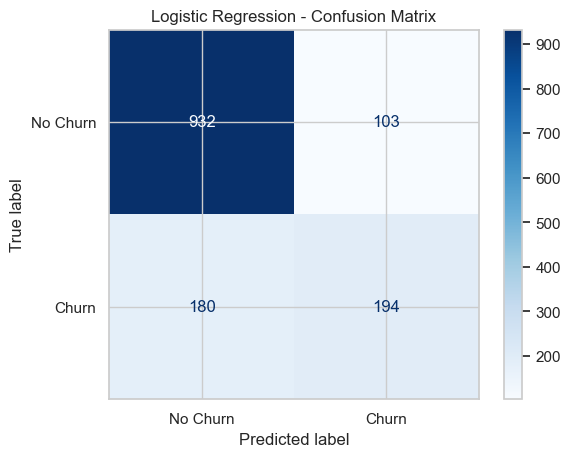

In [112]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

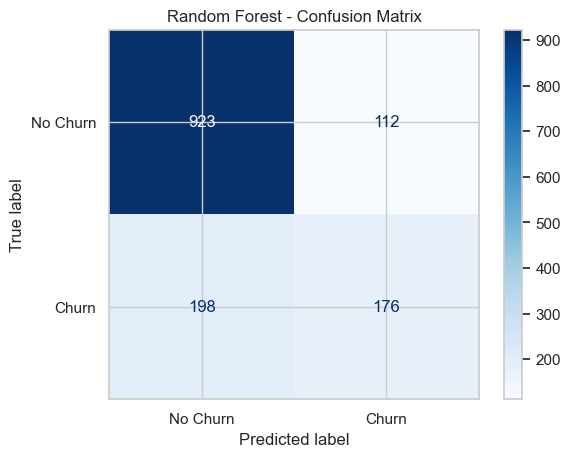

In [114]:
# Create confusion matrix for Random Forest
cm_rf = confusion_matrix(y_test, rf_predictions)

# Display confusion matrix
display_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Churn", "Churn"]
)

display_rf.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [121]:
# Get the trained Random Forest model
rf_classifier = rf_model.named_steps["randomforestclassifier"]

# Get the fitted preprocessor
fitted_preprocessor = rf_model.named_steps["columntransformer"]

# Get numerical feature names
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Get categorical feature names
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Get encoded categorical feature names
encoded_features = (
    fitted_preprocessor
    .named_transformers_["categories"]
    .named_steps["encoder"]
    .get_feature_names_out(categorical_features)
)

# Combine all feature names
feature_names = numeric_features + list(encoded_features)

# Get importance scores
importance = rf_classifier.feature_importances_

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

# Display top 10 features
print(feature_importance.head(10))

                           Feature  Importance
3                     TotalCharges    0.143604
2                   MonthlyCharges    0.127829
1                           tenure    0.127150
37         Contract_Month-to-month    0.040833
44  PaymentMethod_Electronic check    0.030405
4                    TotalServices    0.029312
19               OnlineSecurity_No    0.028968
17     InternetService_Fiber optic    0.028735
28                  TechSupport_No    0.027926
46         TenureGroup_0-12 Months    0.019333


In [123]:
from IPython.display import display
display(feature_importance.head(10))

# Create model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression (Balanced)",
        "Random Forest"
    ],
    "Accuracy": [
        0.7991,
        0.7331,
        0.7800
    ],
    "Churn Recall": [
        0.52,
        0.79,
        0.47
    ],
    "Churn F1-Score": [
        0.58,
        0.61,
        0.53
    ]
})

display(model_comparison)

,Feature,Importance
3,TotalCharges,0.143604
2,MonthlyCharges,0.127829
1,tenure,0.127150
37,Contract_Month-to-month,0.040833
44,PaymentMethod_Electronic check,0.030405
4,TotalServices,0.029312
19,OnlineSecurity_No,0.028968
17,InternetService_Fiber optic,0.028735
28,TechSupport_No,0.027926
46,TenureGroup_0-12 Months,0.019333


,Model,Accuracy,Churn Recall,Churn F1-Score
0,Logistic Regression,0.7991,0.52,0.58
1,Logistic Regression (Balanced),0.7331,0.79,0.61
2,Random Forest,0.7800,0.47,0.53


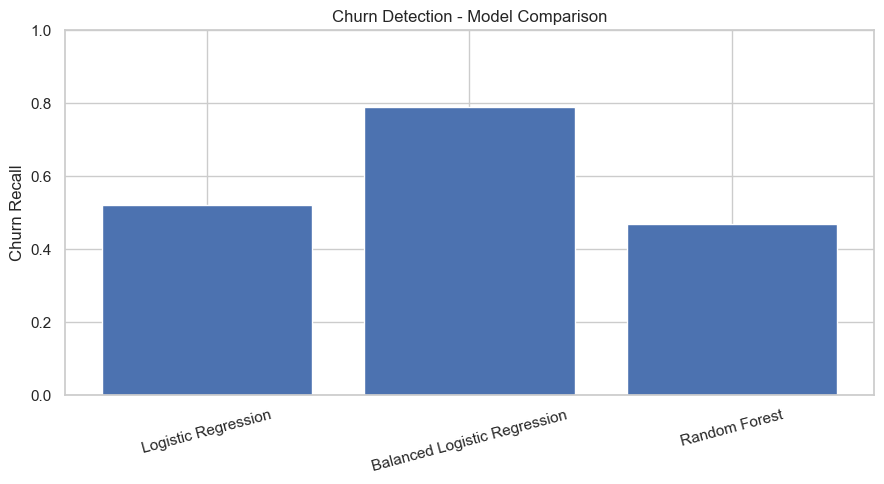

In [124]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "Balanced Logistic Regression",
    "Random Forest"
]

recalls = [0.52, 0.79, 0.47]

plt.figure(figsize=(9, 5))
plt.bar(models, recalls)

plt.title("Churn Detection - Model Comparison")
plt.ylabel("Churn Recall")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()